In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display, Math

from src.grid import Grid, PolarGrid
from src.elementary_solutions import SourceSink, Doublet, UniformFlow
from src.superposition import DoubletFreestream

ModuleNotFoundError: No module named 'src'

## 1. Complex numbers in Python

In [ ]:
3 + 2j

(3+2j)

In [ ]:
a = 3
b= 3
z = a + b * 1j
print ('z = ', z)
print('The type of the variable is ', type(z))

z =  (3+3j)
The type of the variable is  <class 'complex'>


In [ ]:
# 1.
z1 = (2.75 + 3.69j) * (8.55 - 6.13j)

display(Math(rf'1.\quad (2.75+3.69i)\times(8.55-6.13i) = {z1.real:.2f}{z1.imag:+.2f}i'))


# 2.

z2 = 1.4 * np.exp(1j*5.32)

display(Math(rf'2.\quad 1.4\times e^{{i\,5.32}} = {z2.real:.2f}{z2.imag:+.2f}i'))

# 3.

z3 = (7.51 - 9.15j) / (4.43 + 9.64j)

display(Math(rf'3. \quad \frac{{7.51-9.15i}}{{4.43+9.64i}} = {z3.real:.2f}{z3.imag:+.2f}i'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 2. Shapes created by the Joukowski transformation

In [ ]:
def joukowski_transformation(z, c):

    return z + c**2 / z

In [ ]:
c = 1

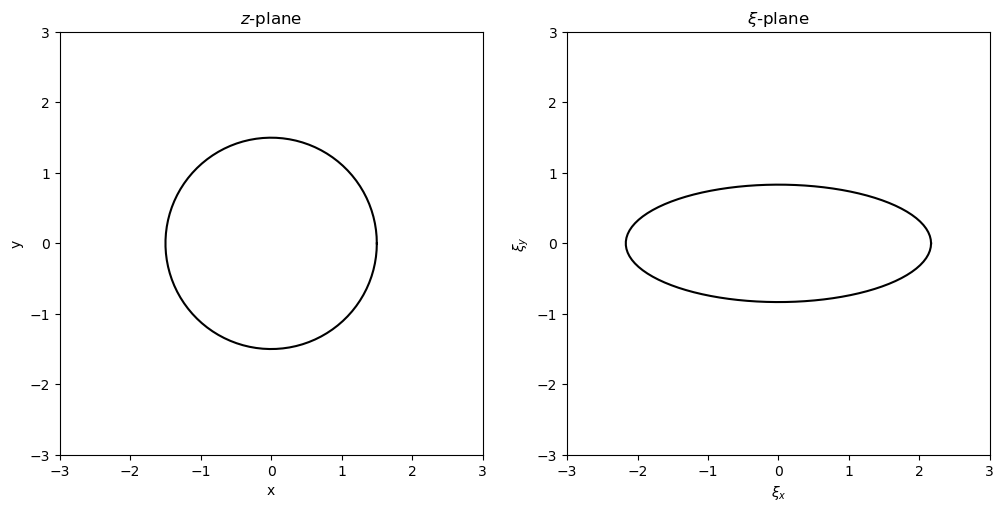

In [ ]:

# 1.

R = 1.5
theta = np.linspace(0, 2 * np.pi, 100)
z = R * np.exp(1j * theta)
xi = joukowski_transformation(z, c)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z.real, z.imag, color='k')
ax[0].set_xlim(-3, 3)
ax[0].set_ylim(-3, 3)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi.real, xi.imag, color='k')
ax[1].set_xlim(-3, 3)
ax[1].set_ylim(-3, 3)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

1. On the $z$-plane, place a circle with radius $R$ larger than $c=1$, say $R=1.5$, centered at the origin. What does the shape look like when mapped on the $\xi$-plane?
    2. ellipse

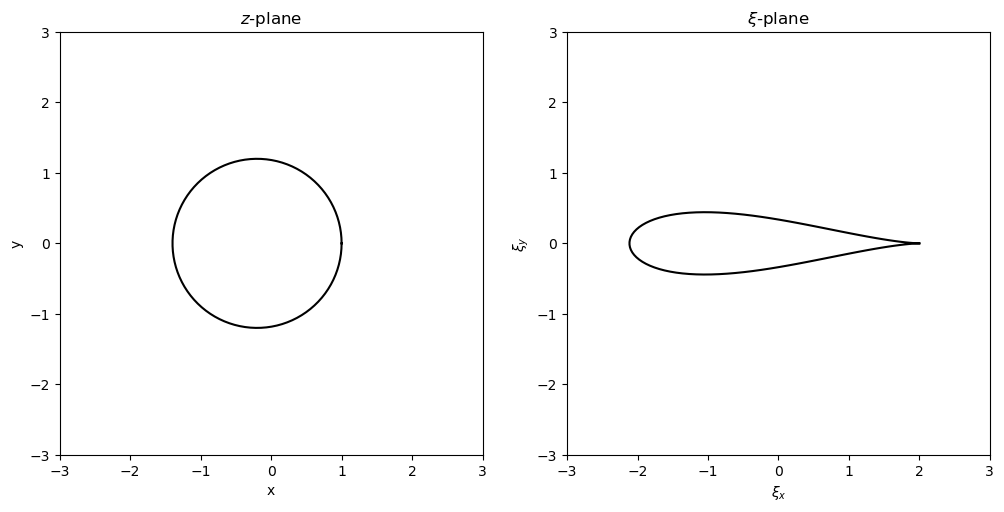

In [ ]:
# 2.

R = 1.2
theta = np.linspace(0, 2 * np.pi, 100)
xc = c - R
yc = 0
z =  (xc + yc * 1j) + R * np.exp(1j * theta)
xi = joukowski_transformation(z, c)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z.real, z.imag, color='k')
ax[0].set_xlim(-3, 3)
ax[0].set_ylim(-3, 3)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi.real, xi.imag, color='k')
ax[1].set_xlim(-3, 3)
ax[1].set_ylim(-3, 3)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

2. Now, place a circle on the $z$-plane with radius such that $c \lt R \lt 2c$ (e.g., $c=1$; $R=1.2$), centered at $(x_c,y_c)=(c-R, 0)$. What does the shape look like on the $\xi$-plane?
    3. symmetric airfoil

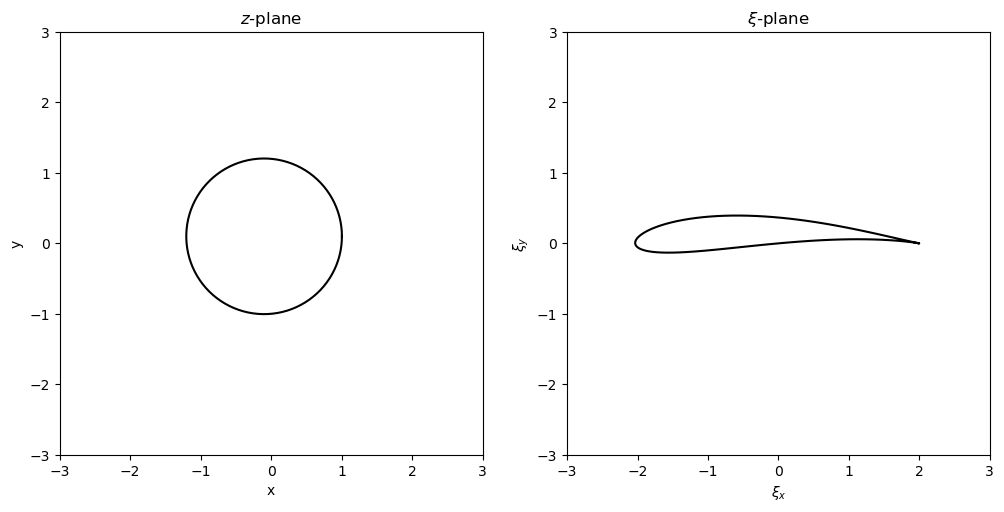

In [ ]:
# 3.

dx = 0.1
dy = 0.1
xc = -dx
yc = dy
R = np.sqrt((c - xc)**2 + yc**2)
theta = np.linspace(0, 2 * np.pi, 100)
z =  (xc + yc * 1j) + R * np.exp(1j * theta)
xi = joukowski_transformation(z, c)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z.real, z.imag, color='k')
ax[0].set_xlim(-3, 3)
ax[0].set_ylim(-3, 3)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi.real, xi.imag, color='k')
ax[1].set_xlim(-3, 3)
ax[1].set_ylim(-3, 3)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

3. Put a circle at $(x_c, y_c)=(-\Delta x, \Delta y)$, where $\Delta x$ and $\Delta y$ are small positive numbers, e.g. $\Delta x=0.1$ and $\Delta y=0.1$. The radius $R$ of the circle is $R = \sqrt{(c - x_c)^2 + y_c^2}$. What does the shape on $\xi$-plane look like?
    4. cambered airfoil

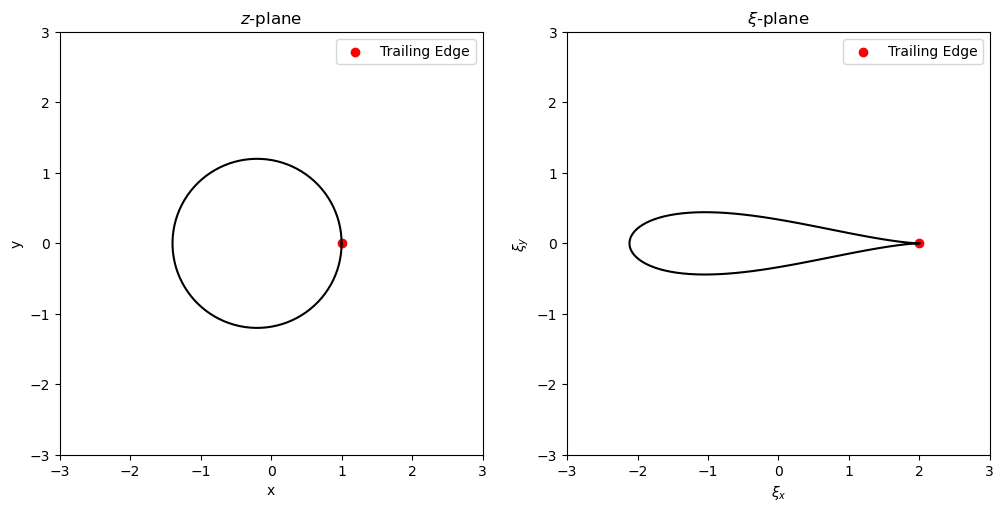

In [ ]:
# 4.

R = 1.2
theta = np.linspace(0, 2 * np.pi, 100)
xc = c - R
yc = 0
z =  (xc + yc * 1j) + R * np.exp(1j * theta)
xi = joukowski_transformation(z, c)
te = np.argmax(xi.real)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z.real, z.imag, color='k')
ax[0].scatter(z[te].real, z.real[te].imag, color='r', label='Trailing Edge')
ax[0].set_xlim(-3, 3)
ax[0].set_ylim(-3, 3)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].legend()
ax[0].set_title('$z$-plane')

ax[1].plot(xi.real, xi.imag, color='k')
ax[1].scatter(xi[te].real, xi[te].imag, color='r', label='Trailing Edge')
ax[1].set_xlim(-3, 3)
ax[1].set_ylim(-3, 3)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].legend()
ax[1].set_title(r'$\xi$-plane')
plt.show()

In [2]:
display(Markdown(rf"""
4. Consider the case when you obtain a symmetric airfoil. In polar coordinates, $(\theta, r=R)$, which point on the circle corresponds to the trailing edge of the airfoil?
    * $\theta={theta[te]:.2f}$ radians
"""))

NameError: name 'theta' is not defined

## 3. Grid points on the $z$-plane using polar coordinates

### Exercise

1. Build a grid in polar coordinates in the $z$-plane. Use $N_r = 100$ points in the radial direction, within the range $R \le r \le 5$, and $N_\theta = 145$ points in the axial direction, within the range $0 \le \theta \le 2\pi$.
2. Use the Joukowski transformation to map the grid into the $\xi$-plane.
3. Plot the grid points in both planes using the function `pyplot.scatter()`.

In [14]:
# 1.
R = 1.15
radius_start, radius_end = R, 5
theta_start, theta_end = 0, 2 * np.pi
nradius, ntheta = 100, 145
xc, yc = -0.15, 0

complex_grid = PolarGrid(radius_start, radius_end, theta_start, theta_end, nradius, ntheta, xc, yc)

c = 1

z = complex_grid.X + complex_grid.Y * 1j

In [15]:
# 2.

xi = joukowski_transformation(z, c)

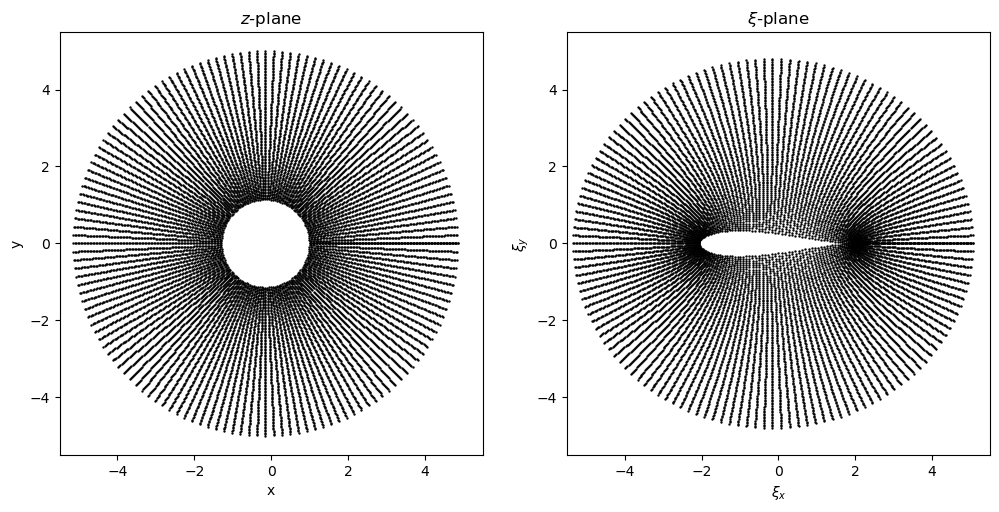

In [16]:
# 3.
x_start, x_end = -5.5, 5.5
y_start, y_end = -5.5, 5.5

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].scatter(z.real, z.imag, color='k', s=0.5, marker='o')
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].scatter(xi.real, xi.imag, color='k', s=0.5, marker='o')
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

## 4. Flow over a symmetric Joukowski airfoil with zero angle of attack

In [17]:
u_inf = 1.0
freestream = UniformFlow(U_inf=u_inf)

In [18]:
kappa = R**2 * 2 * np.pi * freestream.U_inf
doublet = Doublet(xd=xc, yd=yc, strength=kappa)

In [19]:
doublet_freestream = DoubletFreestream(doublet, freestream)
psi = doublet_freestream.stream_function(complex_grid)

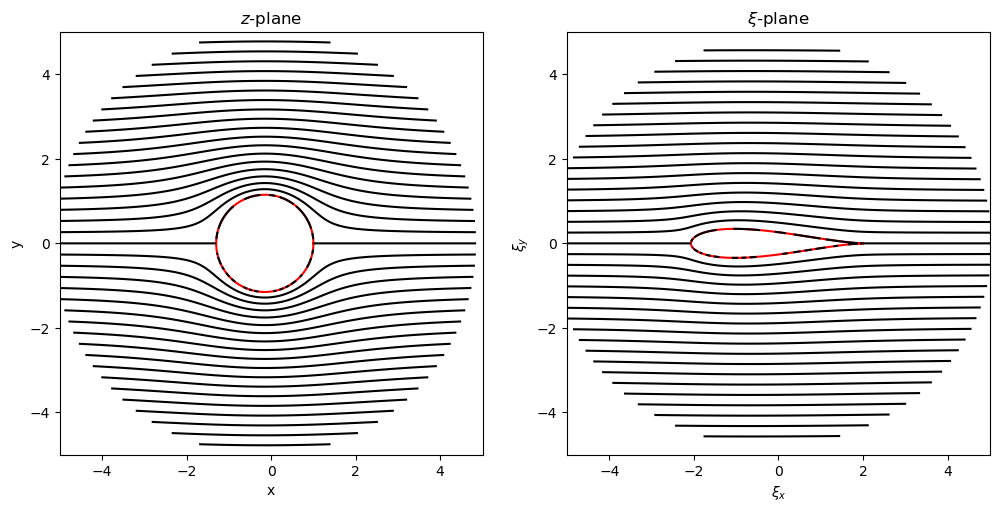

In [20]:
# 3.
x_start, x_end = -5, 5
y_start, y_end = -5, 5

z_circle = (xc + yc * 1j) + R * np.exp(1j * theta)
xi_circle = joukowski_transformation(z_circle, c)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z_circle.real, z_circle.imag, color='r')
ax[0].contour(z.real, z.imag, psi,
              levels=np.linspace(y_start, y_end, 41), colors='k', linestyles='solid')
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].contour(xi.real, xi.imag, psi,
              levels=np.linspace(y_start, y_end, 41), colors='k', linestyles='solid')
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

In [21]:
u, v = doublet_freestream.velocity_field(complex_grid)

w_z = u - v * 1j
w_xi = w_z / (1 - (c/z)**2)

u_xi = w_xi.real
v_xi = -w_xi.imag

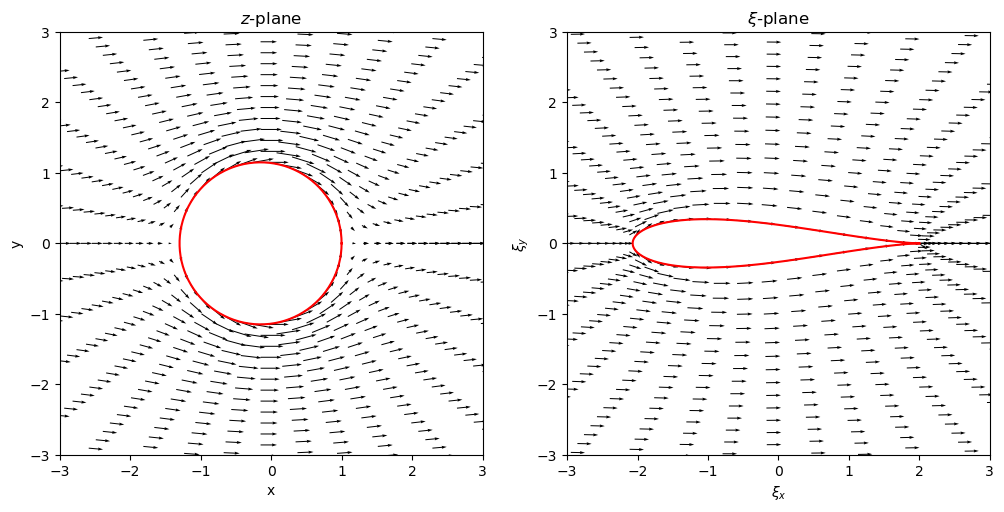

In [22]:
# 3.
x_start, x_end = -3, 3
y_start, y_end = -3, 3

steps = 4

z_circle = (xc + yc * 1j) + R * np.exp(1j * theta)
xi_circle = joukowski_transformation(z_circle, c)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z_circle.real, z_circle.imag, color='r')
ax[0].quiver(
    z.real[::steps, ::steps], 
    z.imag[::steps, ::steps], 
    u[::steps, ::steps], 
    v[::steps, ::steps], 
    scale=30
)
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].quiver(
    xi.real[::steps, ::steps], 
    xi.imag[::steps, ::steps], 
    u_xi[::steps, ::steps], 
    v_xi[::steps, ::steps], 
    scale=30
)
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

In [23]:
cp_z = doublet_freestream.pressure_coefficient(complex_grid)

cp_xi = 1 - (np.abs(w_xi) / freestream.U_inf)**2

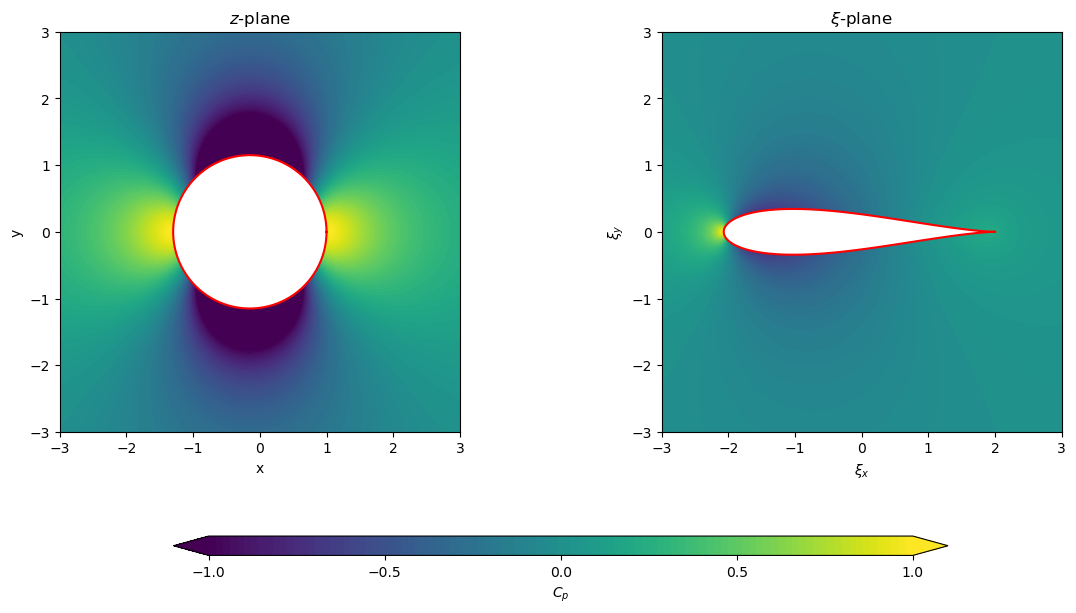

In [24]:
# 3.
x_start, x_end = -3, 3
y_start, y_end = -3, 3

steps = 4
levels = np.linspace(-1, 1, 100)

z_circle = (xc + yc * 1j) + R * np.exp(1j * theta)
xi_circle = joukowski_transformation(z_circle, c)

fig, ax = plt.subplots(1, 2, figsize=(12, 6), layout='constrained')
ax[0].plot(z_circle.real, z_circle.imag, color='r')
contf = ax[0].contourf(z.real, z.imag, cp_z,
              levels=levels, cmap='viridis', extend='both')
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].contourf(xi.real, xi.imag, cp_xi,
              levels=levels, cmap='viridis', extend='both')
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')

cbar = fig.colorbar(
    contf, ax=ax,
    location='bottom',
    shrink=0.65,
    aspect=40,
    pad=0.12
)
cbar.set_label('$C_p$')
cbar.set_ticks(np.linspace(-1, 1, 5))

plt.show()

In [25]:
display(Markdown(rf"""
### Exercise

* Write the Python code to obtain the figures shown above (streamlines, velocity field, and pressure coefficient in both planes).
* Answer the following questions:
    1. What is the strength of the doublet? $\kappa={kappa:.2f}$
    2. What is the velocity at the $62^\text{{nd}}$ point on the airfoil surface? 
    (We assume that the trailing edge is the $1^\text{{st}}$ point and that we index the points counterclockwise.)
    $|W_\xi|$={np.abs(w_xi[61, 0]):.2f}
    3. What is the minimum value of the pressure coefficient on the airfoil surface?
    $Cp$={np.nanmin(cp_xi[:, 0]):.2f}   
"""))


### Exercise

* Write the Python code to obtain the figures shown above (streamlines, velocity field, and pressure coefficient in both planes).
* Answer the following questions:
    1. What is the strength of the doublet? $\kappa=8.31$
    2. What is the velocity at the $62^\text{nd}$ point on the airfoil surface? 
    (We assume that the trailing edge is the $1^\text{st}$ point and that we index the points counterclockwise.)
    $|W_\xi|$=1.22
    3. What is the minimum value of the pressure coefficient on the airfoil surface?
    $Cp$=-0.69   


## 5. Flow over a symmetric Joukowski airfoil with non-zero angle of attack, without circulation

In [26]:
aoa = np.deg2rad(20)

z_prime = (z - (xc + yc * 1j)) * np.exp(-1j*aoa)

In [27]:
complex_grid_prime = complex_grid

complex_grid_prime.X = z_prime.real
complex_grid_prime.Y = z_prime.imag

In [28]:
xc_prime, yc_prime = 0.0, 0.0

doublet = Doublet(xd=xc_prime, yd=yc_prime, strength=kappa)

In [29]:
doublet_freestream = DoubletFreestream(doublet, freestream)
psi = doublet_freestream.stream_function(complex_grid_prime)

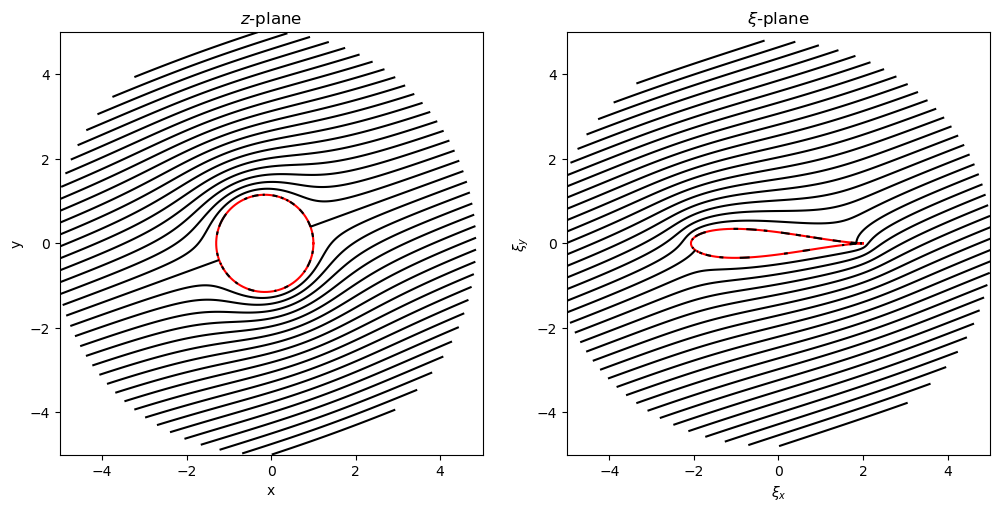

In [30]:
# 3.
x_start, x_end = -5, 5
y_start, y_end = -5, 5

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z_circle.real, z_circle.imag, color='r')
ax[0].contour(z.real, z.imag, psi,
              levels=np.linspace(y_start, y_end, 41), colors='k', linestyles='solid')
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].contour(xi.real, xi.imag, psi,
              levels=np.linspace(y_start, y_end, 41), colors='k', linestyles='solid')
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

In [31]:
u_prime, v_prime = doublet_freestream.velocity_field(complex_grid_prime)

w_z_prime = u_prime - v_prime * 1j
w_z = w_z_prime * np.exp(-1j * aoa)
u_z = w_z.real
v_z = -w_z.imag

w_xi = w_z / (1 - (c/z)**2)
u_xi = w_xi.real
v_xi = -w_xi.imag

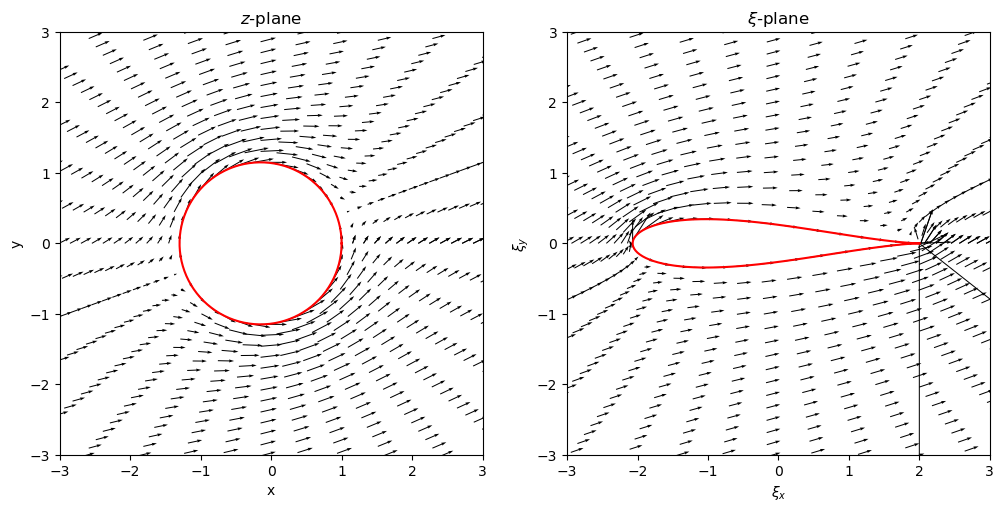

In [32]:
# 3.
x_start, x_end = -3, 3
y_start, y_end = -3, 3

steps = 4

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z_circle.real, z_circle.imag, color='r')
ax[0].quiver(
    z.real[::steps, ::steps], 
    z.imag[::steps, ::steps], 
    u_z[::steps, ::steps], 
    v_z[::steps, ::steps], 
    scale=30
)
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].quiver(
    xi.real[::steps, ::steps], 
    xi.imag[::steps, ::steps], 
    u_xi[::steps, ::steps], 
    v_xi[::steps, ::steps], 
    scale=30
)
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

In [33]:
cp_z = doublet_freestream.pressure_coefficient(complex_grid_prime)

cp_xi = 1 - (np.abs(w_xi) / freestream.U_inf)**2

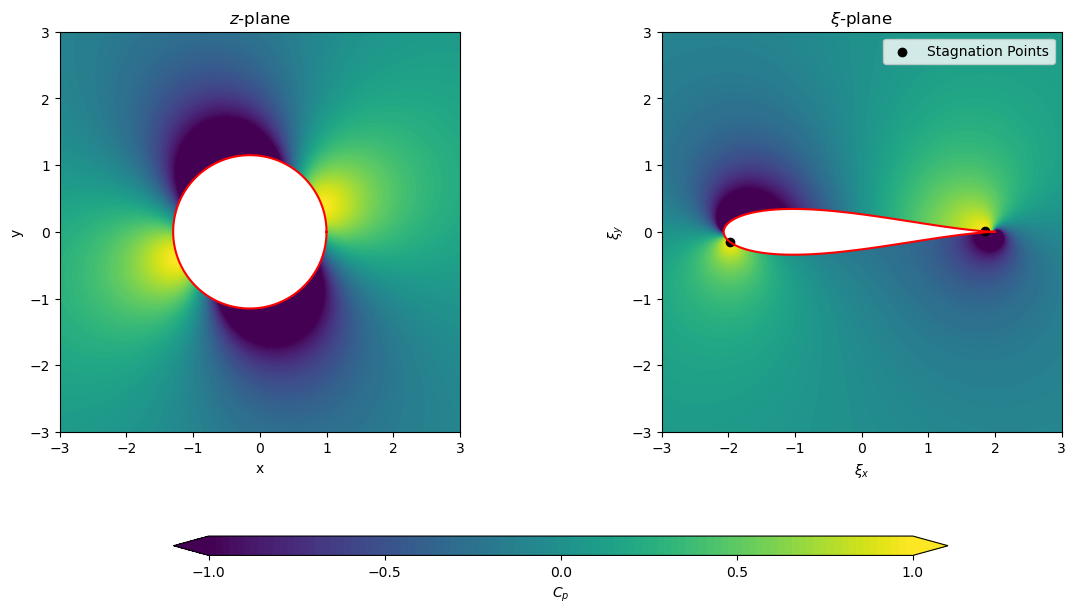

In [66]:
# 3.
x_start, x_end = -3, 3
y_start, y_end = -3, 3

steps = 4
levels = np.linspace(-1, 1, 100)

z_circle = (xc + yc * 1j) + R * np.exp(1j * theta)
xi_circle = joukowski_transformation(z_circle, c)

stag_mask = np.abs(w_xi) < 1e-6

x_stag_xi = xi.real[stag_mask]
y_stag_xi = xi.imag[stag_mask]

fig, ax = plt.subplots(1, 2, figsize=(12, 6), layout='constrained')
ax[0].plot(z_circle.real, z_circle.imag, color='r')
contf = ax[0].contourf(z.real, z.imag, cp_z,
              levels=levels, cmap='viridis', extend='both')
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].contourf(xi.real, xi.imag, cp_xi,
              levels=levels, cmap='viridis', extend='both')
ax[1].scatter(x_stag_xi, y_stag_xi, c='k', label='Stagnation Points')
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].legend()
ax[1].set_title(r'$\xi$-plane')

cbar = fig.colorbar(
    contf, ax=ax,
    location='bottom',
    shrink=0.65,
    aspect=40,
    pad=0.12
)
cbar.set_label('$C_p$')
cbar.set_ticks(np.linspace(-1, 1, 5))

plt.show()

### Exercise

* Write the Python code to obtain the figures shown above (streamlines, velocity field, and pressure coefficient in the $z$ and $\xi$ planes). Set the angle of attack to $\text{AoA} = 20^\circ$.
* Answer the following questions:
    1. Do you think the flow over the airfoil looks reasonable? Explain why.
    No I don't think the flow over the airfoil looks reasonable, because at the trailing edge the flow shouldn't go over the latest level, this is unphysical.
    2. What are the index of the stagnation points on the airfoil? (We assume that the trailing edge is the $1^\text{st}$ point and that we index the points counterclockwise.)
    
    3. How much is the lift? The lift, $L=-\oint p \times \sin{\theta} dA$, is perpendicular to the free-stream direction.
    4. How much is the drag? The drag, $D=-\oint p \times \cos{\theta} dA$, is in the direction of the free-stream.
    5. What is the velocity at the $50^\text{th}$ point on the airfoil?
    6. What is the pressure coefficient at the $75^\text{th}$ point on the airfoil?

Don't forget to enter your answers on [Open edX](https://openedx.seas.gwu.edu/courses/course-v1:MAE+MAE6226+2017/about).
(Notes: you will need to enter your results with a 2-digit precision after the decimal point in the auto-graded section.)

In [ ]:
display(Markdown(rf"""
### Exercise

* Write the Python code to obtain the figures shown above (streamlines, velocity field, and pressure coefficient in the $z$ and $\xi$ planes). Set the angle of attack to $\text{{AoA}} = 20^\circ$.
* Answer the following questions:
    1. Do you think the flow over the airfoil looks reasonable? Explain why.
    No I don't think the flow over the airfoil looks reasonable, because at the trailing edge the flow shouldn't go over the latest level, this is unphysical.
    2. What are the index of the stagnation points on the airfoil? (We assume that the trailing edge is the $1^\text{{st}}$ point and that we index the points counterclockwise.)
    Indices = {np.argwhere(stag_mask) + 1}
    3. How much is the lift? The lift, $L=-\oint p \times \sin{{\theta}} dA$, is perpendicular to the free-stream direction.
    
    4. How much is the drag? The drag, $D=-\oint p \times \cos{{\theta}} dA$, is in the direction of the free-stream.

    5. What is the velocity at the $50^\text{{th}}$ point on the airfoil?
    6. What is the pressure coefficient at the $75^\text{{th}}$ point on the airfoil?  
"""))


### Exercise

* Write the Python code to obtain the figures shown above (streamlines, velocity field, and pressure coefficient in the $z$ and $\xi$ planes). Set the angle of attack to $\text{AoA} = 20^\circ$.
* Answer the following questions:
    1. Do you think the flow over the airfoil looks reasonable? Explain why.
    No I don't think the flow over the airfoil looks reasonable, because at the trailing edge the flow shouldn't go over the latest level, this is unphysical.
    2. What are the index of the stagnation points on the airfoil? (We assume that the trailing edge is the $1^\text{st}$ point and that we index the points counterclockwise.)
    Indices = [[ 9  1]
 [81  1]]
    3. How much is the lift? The lift, $L=-\oint p \times \sin{\theta} dA$, is perpendicular to the free-stream direction.
    4. How much is the drag? The drag, $D=-\oint p \times \cos{\theta} dA$, is in the direction of the free-stream.
    5. What is the velocity at the $50^\text{th}$ point on the airfoil?
    6. What is the pressure coefficient at the $75^\text{th}$ point on the airfoil?  


In [68]:
display(Markdown(rf"""
### Exercise

* Write the Python code to obtain the figures shown above (streamlines, velocity field, and pressure coefficient in both planes).
* Answer the following questions:
    1. What is the strength of the doublet? $\kappa={kappa:.2f}$
    2. What is the velocity at the $62^\text{{nd}}$ point on the airfoil surface? 
    (We assume that the trailing edge is the $1^\text{{st}}$ point and that we index the points counterclockwise.)
    $|W_\xi|$={np.abs(w_xi[61, 0]):.2f}
    3. What is the minimum value of the pressure coefficient on the airfoil surface?
    $Cp$={np.nanmin(cp_xi[:, 0]):.2f}   
"""))


### Exercise

* Write the Python code to obtain the figures shown above (streamlines, velocity field, and pressure coefficient in both planes).
* Answer the following questions:
    1. What is the strength of the doublet? $\kappa=8.31$
    2. What is the velocity at the $62^\text{nd}$ point on the airfoil surface? 
    (We assume that the trailing edge is the $1^\text{st}$ point and that we index the points counterclockwise.)
    $|W_\xi|$=1.95
    3. What is the minimum value of the pressure coefficient on the airfoil surface?
    $Cp$=-2372591216855656929729663991808.00   
